# TPCEmulator: TPC の応答

TPC のガスでのエネルギー損失から、µ-PIC のエンコーダのヒット(ストリップ × クロック)と FADC の波形を作ります。
実データの `ReadData` が読むのと同じ中身になります。

| | |
| --- | --- |
| SMILE_tool_box | `TPC_emulator`(ver 0.41) |
| ソース | `simulation_source/modules/TPCEmulator/`(種電子の数の表 `CalcCluster` とドリフト電場の補正 `FiducialModify` は `simulation_source/vendor/tpc_emu/`) |

## 1. 何をするか

イベントごとに、`EdepPickUp` の TPC のステップ 1 つずつについて:

1. **電離**: エネルギー損失から種電子の数を決める(`Calc_Mode_Cluster = 0`: クラスタの大きさの表 `ClusterData`、1: Poisson × Fano、W 値 `w_value`)
2. **拡散**: 種電子 1 つずつ、ドリフトの長さ(z)に応じて横 `DiffTrans`・縦 `DiffLong` × √(z [cm]) のガウス分布でずらす
3. **ドリフト**: 位置をストリップの番号(ピッチ `ReadOutPitch`)に、z を時刻(`DriftVel`、オフセット `Offset_for_ETCC` − 5)に直す。
   `Fiducial_Modify_Flag = 1` ならドリフト電場のゆがみを解析的な関数で入れる。GEM の隙間に落ちた電子は捨てる
4. **増幅**: GEM(平均 `GEM_Gain` の幾何分布)× µ-PIC(Polya 分布、平均はゲインマップ `GainMap` の Ka から。`Gain_Modify_Amp` で割る)
5. **エレキの応答**: 応答のテンプレート(`IwakiTemplate`)を時刻方向に重ね、ストリップ × クロックの地図を作る

それから、10 ns のクロック 1024 個 × 4 ASIC × ボードごとに:

6. **FADC**: 32 ストリップ(参照と同じく 33 ストリップ)分の和 + 白色ノイズ(`BaseLineFluctuation`)+ ETCC モードのノイズ(`daq_mode = 3`)を
   ADC に直し、2 クロックに 1 つ記録(512 点)
7. **ヒット**: ASIC の和が閾値(`Vth_Anode`, `Vth_Cathode` と `DAC_Survey` から決まる電圧)を超えたクロックで、閾値を超えたストリップを記録

## 2. パラメータ

| パラメータ | 型 | 既定値(C++) | この設定の値 | 単位 | 説明 |
| --- | --- | --- | --- | --- | --- |
| `w_value` | double | 27.22(26.4×0.95 + 54×0.03 + 26×0.02) | 27.22 | eV | W 値(1 電子を作るのに要るエネルギー)[eV] |
| `Fano_Factor` | double | 0.2 | 0.2 | dimensionless | Fano 因子(Calc_Mode_Cluster = 1 のとき)[無次元] |
| `DriftVel` | double | 35.0 | 38.0 | um/ns (= mm/us) | ドリフト速度 [µm/ns = mm/µs] |
| `DiffTrans` | double | 0.26 | 0.26 | mm/sqrt(cm) | 横方向の拡散 [mm/√cm] |
| `DiffLong` | double | 0.24 | 0.24 | mm/sqrt(cm) | 縦方向の拡散 [mm/√cm] |
| `ReadOutPitch` | double | 0.8 | 0.8 | mm | ストリップのピッチ [mm] |
| `GEM_Gain` | double | 20 | 20.0 | dimensionless | GEM の平均の増幅率 [無次元] |
| `IwakiTemplate` | string | (空) | {sim_data}/IwakiTemp.root |  | エレキの応答のテンプレート(IwakiTemp.root) |
| `GainMap` | string | (空) | {data_top}/param/20190528/Calibration20190130.dat |  | µ-PIC の増幅率を決める TPC のゲインマップ(Calibration*.dat) |
| `ClusterData` | string | (空) | {sim_data}/cluster.txt |  | エネルギー損失ごとのクラスタの大きさ(種電子の数)の表(cluster.txt) |
| `BaseLineFluctuation` | double | 21.481 | 21.481 | mV (sigma of the white noise) | 白色ノイズの標準偏差 [mV] |
| `Vth_Anode` | int | 7500 | 6000 | DAC counts (Vth = (DAC_Survey - Vth_Anode) / 2^13 x 3.3 V) | アノードの閾値の DAC の値(Vth = (DAC_Survey − Vth_Anode) / 2^13 × 3.3 V)[DAC counts] |
| `Vth_Cathode` | int | 10500 | 12000 | DAC counts ((Vth_Cathode - DAC_Survey) / 2^13 x 3.3 V) | カソードの閾値の DAC の値(Vth = (Vth_Cathode − DAC_Survey) / 2^13 × 3.3 V)[DAC counts] |
| `DAC_Survey` | int | 9000 | 9000 | DAC counts | 閾値の基準の DAC の値 [DAC counts] |
| `Offset_for_TPC` | int | 85 | 85 | clock (10 ns) | TPC モードの時刻のオフセット [clock, 10 ns] |
| `Offset_for_ETCC` | int | 85 | 85 | clock (10 ns) | ETCC モードの時刻のオフセット(内部で −5)[clock, 10 ns] |
| `Gain_Modify_Amp` | double | 1 | 1.0651 | dimensionless | ゲインマップの Ka を割る係数 [無次元] |
| `Debug_Mode` | int | 0 | 0 |  | 1: TPC モードの時刻のずらしをしない |
| `Calc_Mode_Cluster` | int | 0 | 0 |  | 種電子の数: 0 クラスタの表、1 Poisson × Fano |
| `Fiducial_Modify_Flag` | int | 1 | 1 |  | 1: ドリフト電場のゆがみを解析的な関数で補正する |
| `upic_size` | double | 30.72 | 30.72 | cm | µ-PIC の一辺 [cm] |
| `drift_offset` | double | 3 | 3.0 | cm | TPC の位置のオフセット [cm] |
| `daq_mode` | int | 3 | 3 |  | DAQ のモード(3: ETCC モードのノイズを足す、1: TPC モード) |
| `random_seed` | int | 4357 | 101 |  | 乱数の種(run_sim.py --seed で上書き) |

この設定の値は、参照のシミュレーションの run の値(`HabocStatus.scl`)です。`random_seed` は `run_sim.py --seed` で `seed × 100 + 2` に上書きされます。
コードの中の固定値: GEM の Polya の形 0.5、µ-PIC の Polya の形 0.65(`TPCEmulator.hh`)。

パラメータは設定ファイル `config/simulation/smile2p_flight_parma_thermal_neutron_d10_raw.json` の `response[TPCEmulator].parameters` に書きます
(書き方は `config/README.md`)。1 回だけ変えて試すときは `run_sim.py ... --set response.TPCEmulator.Vth_Anode=6500` で上書きします。
「既定値(C++)」は設定ファイルに書かなかったときの値です。

## 3. ほかのモジュールとのやり取り

受け取るもの: `EdepPickUp` の `TPCStepE()`, `TPCStepX/Y/Z()`, `EventID()`。

| 関数 | 型 | 単位 | 中身 | 使うモジュール |
| --- | --- | --- | --- | --- |
| `NBoard()` | int | | エンコーダのボードの数(`upic_size / ReadOutPitch / 128` の切り上げ = 3) | RawWriter2p |
| `EventID()` | unsigned | | イベント番号(`EdepPickUp::EventID()`) | |
| `EventTime()` | unsigned | 10 ms | イベントの時刻(実行を始めてからの経過時間 × 100、参照と同じ) | RawWriter2p |
| `Hits(side, board)` | vector<unsigned> | | ヒットの記録(1 ヒット 5 語: クロック、4 ASIC × 32 ストリップのビット)。side 0 アノード、1 カソード | RawWriter2p |
| `NHit(side, board)` | int | | そのボードのヒットの数 | RawWriter2p |
| `FADC(side, board)` | const unsigned short*(4 × 512) | ADC | FADC の波形(4 ASIC × 512 点) | RawWriter2p |
| `DriftVelocity()` | double | µm/ns | `DriftVel` | |

## 4. 確かめる

作ったヒットと波形を、raw ファイルを `ReadData → RawTreeWriter` で読み直したツリー(実データと同じ形)で見ます。

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_sim.py").exists())
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CONFIG = "smile2p_flight_parma_thermal_neutron_d10_raw"
cfg = ec.load_sim(CONFIG)
# 1_DataIO/DataIO_example.ipynb の出力(d10 の熱中性子、100 万個、seed 1)を使う
SIM = REPO / "tutorials_simulation" / "cache" / "d10_seed1_1M"
EDEP, RAW = SIM / "edep.root", SIM / "raw"
assert EDEP.exists(), "先に ../../DataIO_example.ipynb を実行してください"

def flat(column):
    # RDataFrame.AsNumpy() の vector 型の列 -> 全イベントをつないだ 1 次元の numpy 配列
    return np.concatenate([np.asarray(v) for v in column]) if len(column) else np.array([])

In [2]:
import subprocess
RAW_TREE = SIM / "raw_tree.root"
cmd = [sys.executable, str(REPO / "run_script" / "run_chain.py"), "smile2p_sim_d10_recon", "-o", str(RAW_TREE), "--raw",
       "--set", f"ReadData.data_dir={RAW}"]
print(" ".join(cmd))
if not RAW_TREE.exists():
    subprocess.run(cmd, capture_output=True, text=True).check_returncode()
raw = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW_TREE)).AsNumpy(["hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock", "fadc_ch", "fadc_wave"])
truth = ROOT.RDataFrame("sim", str(RAW / "sim_truth.root")).AsNumpy(["E_tpc"])
nhit = np.array([len(v) for v in raw["hit_a_strip"]]) + np.array([len(v) for v in raw["hit_c_strip"]])
print("events:", len(nhit))

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_sim_d10_recon -o /home/onoda/ANLNext/EricaNext_try/tutorials_simulation/cache/d10_seed1_1M/raw_tree.root --raw --set ReadData.data_dir=/home/onoda/ANLNext/EricaNext_try/tutorials_simulation/cache/d10_seed1_1M/raw


events: 270


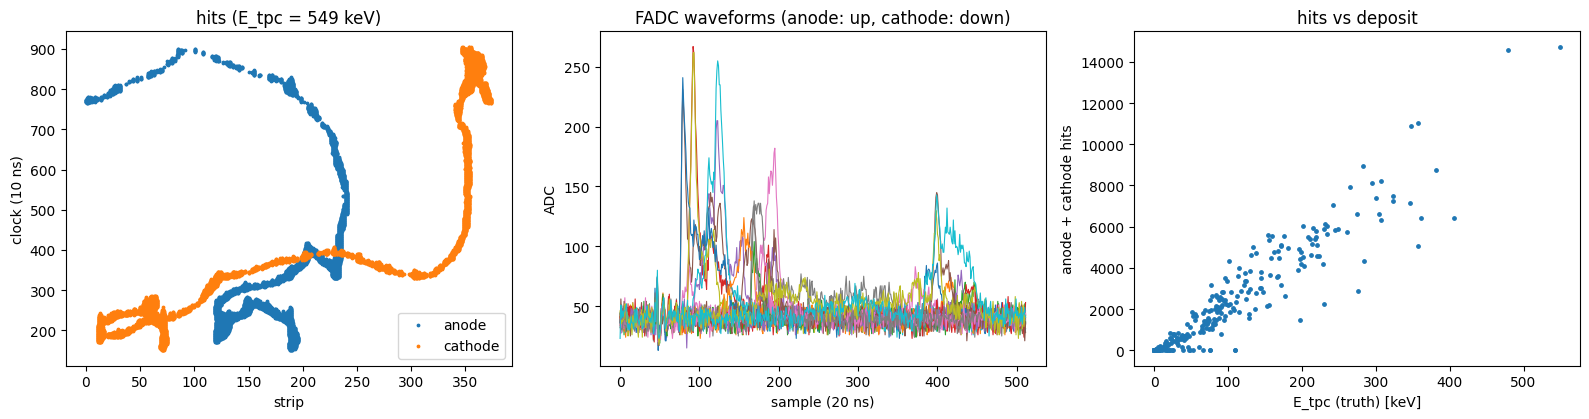

In [3]:
i = int(np.argmax(truth["E_tpc"]))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].scatter(raw["hit_a_strip"][i], raw["hit_a_clock"][i], s=3, label="anode")
ax[0].scatter(raw["hit_c_strip"][i], raw["hit_c_clock"][i], s=3, label="cathode")
ax[0].set_xlabel("strip"); ax[0].set_ylabel("clock (10 ns)"); ax[0].legend(); ax[0].set_title(f"hits (E_tpc = {truth['E_tpc'][i]:.0f} keV)")
ch, wave = np.asarray(raw["fadc_ch"][i]), np.asarray(raw["fadc_wave"][i]).reshape(-1, 512)
for c, w in zip(ch, wave):
    ax[1].plot(w, lw=0.8, label=f"ch {c}")
ax[1].set_xlabel("sample (20 ns)"); ax[1].set_ylabel("ADC"); ax[1].set_title("FADC waveforms (anode: up, cathode: down)")
ax[2].scatter(truth["E_tpc"], nhit, s=6); ax[2].set_xlabel("E_tpc (truth) [keV]"); ax[2].set_ylabel("anode + cathode hits")
ax[2].set_title("hits vs deposit")
fig.tight_layout(); plt.show()

- 左: 1 イベントのヒット。アノード(x 方向のストリップ)とカソード(y 方向)で、クロック(ドリフトの時間 = z)が同じ範囲に並びます。
- 中: FADC の波形。アノードは上向き、カソードは下向きに出ます(実データと同じ形)。
- 右: ヒットの数はエネルギー損失(とその飛跡の長さ)とともに増えます。

TPC の信号の大きさは参照(SMILE_tool_box)より約 10 % 大きいことが分かっています(Geant4 のステップの細かさの違い。`docs/simulation_port_log.md`)。